# Atividade: Suavização, Remoção de Ruído e Detecção de Bordas
**Unidade:** 2 | **Capítulo:** 1 | **Tarefa:** 1


## Introdução

O mini dataset construído na atividade anterior contém 10 imagens em duas classes: **Classe A: Controle** (img001 a img005) e **Classe B: Nintendo Switch** (img006 a img010), capturadas com um Samsung A34 5G sob cinco cenários de iluminação, replicados nas duas classes.

O objetivo desta atividade é aplicar filtros de suavização (média, Gaussiano e mediana) e operadores de detecção de bordas (Sobel, Prewitt e Canny) em quatro imagens desse dataset, avaliando qual filtro é mais adequado ao tipo de degradação presente e se a suavização prévia melhora a detecção de bordas.

As conclusões combinam **evidência quantitativa** (média, variância e contagem de pixels de borda) e **observação visual**, mantidas separadas ao longo do notebook.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from google.colab import drive

drive.mount('/content/drive')
PATH = '/content/drive/MyDrive/dataset'

# 'nearest' evita que o proprio matplotlib suavize a imagem ao exibi-la
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Parte 1: Seleção das Imagens

Foram escolhidos os cenários 3 (luz artificial noturna, distância longa) e 5 (luz mista) nas duas classes — os de menor disponibilidade de luz. Usar os mesmos cenários em A e B mantém a condição de captura controlada na comparação entre classes. Os parâmetros foram consultados na galeria do aparelho, já que os arquivos `.jpg` perderam o EXIF na conversão HEIC → JPG da atividade anterior.

### Classe A (Controle)
* **Imagem 1:** `img003_original.jpg` — ISO 4000, 1/4 s, ƒ/1.8, BV −6,62
  * **Degradação observada:** granulação fina no fundo de cerâmica, variações aleatórias de intensidade nas sombras e perda de microtextura no plástico, que aparenta aspecto liso.
  * **Hipótese de origem:** foto noturna com pouca luz; o celular elevou o ISO a 4000 (~40× o ganho base), amplificando o ruído de leitura do sensor e o *shot noise*, que pesam mais nas áreas escuras. A exposição de 1/4 s soma *dark current*. O aspecto liso indica que a câmera já aplicou redução de ruído interna, trocando ruído por perda de detalhe.

* **Imagem 2:** `img005_original.jpg` — ISO 800, 1/20 s, ƒ/1.8, BV −1,80
  * **Degradação observada:** ruído de luminância baixo, perda de definição na textura do tecido de fundo e tons escuros do plástico achatados.
  * **Hipótese de origem:** ganho intermediário (~8×), com ruído de sensor controlado. A degradação visível vem do processamento: redução de ruído interna e compressão com perdas. Caso de degradação leve, em contraste com a img003.

### Classe B (Nintendo Switch)
* **Imagem 3:** `img008_original.jpg` — ISO 4000, 1/4 s, ƒ/1.8, BV −6,62
  * **Degradação observada:** granulação fina no fundo, semelhante à img003, mais perceptível na tela escura do console; baixo contraste entre objeto e fundo.
  * **Hipótese de origem:** mesmo cenário da img003, isolando o objeto como única variável. O ruído mais visível na tela escura confirma o comportamento do ruído de leitura: sendo aproximadamente constante, pesa mais onde o sinal é baixo.

* **Imagem 4:** `img010_original.jpg` — ISO 800, 1/20 s, ƒ/1.8, BV −1,80
  * **Degradação observada:** ruído de luminância baixo; reflexo especular ocupando a tela do console; perda de detalhe fino no tecido de fundo.
  * **Hipótese de origem:** mesmo cenário da img005. O principal problema não é ruído de sensor, mas o reflexo na tela — um artefato de aquisição que introduz bordas fortes que não pertencem ao objeto.

### Carregamento e região de interesse (ROI)

As imagens têm 8000×6000 px (48 MP). Para viabilizar o processamento, cada uma é **recortada** em uma região que contém o objeto inteiro e parte do fundo. Recortar, e não redimensionar, é intencional: o redimensionamento calcula médias de pixels vizinhos — ou seja, é uma suavização — e alteraria o ruído antes do experimento.

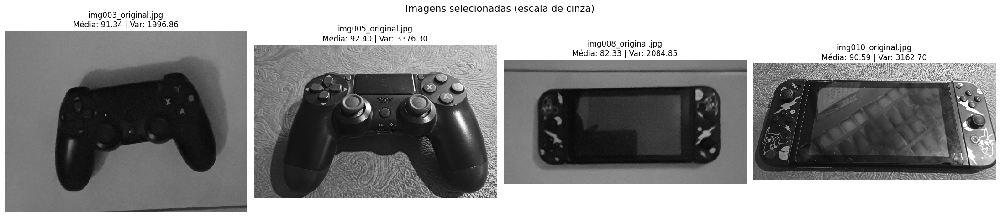

In [ ]:
# nome, classe e ROI (x0, y0, largura, altura)
selecao = [
    ('img003_original.jpg', 'A', (2100, 2600, 3200, 2400)),
    ('img005_original.jpg', 'A', ( 800, 1700, 6300, 4000)),
    ('img008_original.jpg', 'B', (2300, 1600, 3900, 2000)),
    ('img010_original.jpg', 'B', ( 250, 1600, 7500, 3600)),
]

imagens = {}
for nome, classe, (x, y, w, h) in selecao:
    caminho = os.path.join(PATH, f'classe_{classe}', nome)
    img = cv2.imread(caminho, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(caminho)
    imagens[nome] = img[y:y+h, x:x+w]

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
fig.suptitle('Imagens selecionadas (escala de cinza)', fontsize=15)
for ax, (nome, img) in zip(axes, imagens.items()):
    ax.imshow(img, vmin=0, vmax=255)
    ax.set_title(f'{nome}\nMédia: {np.mean(img):.2f} | Var: {np.var(img):.2f}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Interpretação da linha de base

| Imagem | Cenário | Média | Variância | Desvio-padrão |
|---|---|---|---|---|
| img003 | Luz artificial noturna | 91,34 | 1996,9 | 44,7 |
| img005 | Luz mista | 92,40 | 3376,3 | 58,1 |
| img008 | Luz artificial noturna | 82,33 | 2084,9 | 45,7 |
| img010 | Luz mista | 90,59 | 3162,7 | 56,2 |

O desvio-padrão (√variância) foi incluído por estar na mesma unidade dos níveis
de cinza: um desvio de 44,7 significa que um pixel típico está a cerca de 45
níveis da média, em uma escala de 0 a 255.

**Maior variância.** As imagens de luz mista (img005 e img010) apresentam a
maior dispersão. Duas causas concorrem e não podem ser isoladas com os dados
disponíveis, já que distância e iluminação variaram simultaneamente: (1) a
combinação de fontes de intensidades distintas produz sombras marcadas e áreas
de alto brilho na mesma cena; (2) nessas imagens o objeto foi registrado a curta
distância, ocupando grande parte do quadro sobre fundo de tecido texturizado,
enquanto nas noturnas o objeto é pequeno e o fundo é cerâmica lisa — mais
estrutura visível implica mais variação legítima de intensidade.

**Menor média.** A img008 é a mais escura (82,33), mas não pela iluminação: a
img003, do mesmo cenário noturno, tem média 91,34, praticamente igual à da
img005 (92,40), de luz mista. A causa é a tela escura do Nintendo Switch, que
domina a área analisada. A média reflete a composição da cena, e não a condição
de captura — o que já revela sua limitação como descritor de qualidade.

**Pares de mesmo cenário.** As variâncias são próximas dentro de cada par
(4,4% de diferença no cenário noturno; 6,3% no de luz mista) e distam cerca de
60% entre os pares. A variação é, portanto, governada pela condição de captura
e pela composição da cena, não pelo objeto nem por processamento interno da
câmera. Isso valida o protocolo simétrico adotado na seleção: usando os mesmos
dois cenários nas duas classes, a condição de captura deixa de ser variável de
confusão na comparação entre Classe A e Classe B.

**A variância corresponde a ruído?** Não. Um desvio-padrão de 45 a 58 níveis
implicaria que cada pixel oscila nessa magnitude por efeito de ruído, o que em
uma escala de 0 a 255 produziria uma imagem visualmente destruída. O valor é
explicado pelo contraste estrutural da cena: a diferença de cerca de 70 níveis
entre o objeto escuro (plástico, 20 a 45) e o fundo claro (cerâmica, 105 a 115),
distribuída por duas regiões extensas, gera exatamente essa ordem de dispersão.

A variância global é dominada por conteúdo legítimo, e o ruído representa
fração reduzida do total. Disso decorre uma **previsão a ser testada na Parte
2**: os filtros devem reduzir a variância em proporção pequena, e a redução
observada corresponderá majoritariamente à supressão de detalhe real, não de
ruído. Confirmada a previsão, ficará estabelecido que a variância global é
inadequada como métrica isolada de qualidade neste conjunto, e que avaliar
"melhora" exigirá critérios adicionais.

## Parte 2: Aplicação de Filtros de Suavização

| Filtro | Tipo | Operação | Ruído que trata melhor |
|---|---|---|---|
| **Média** | Linear | Média simples da vizinhança | Gaussiano (mas borra muito) |
| **Gaussiano** | Linear | Média ponderada pela distância | Gaussiano / de sensor |
| **Mediana** | Não linear | Valor central da vizinhança ordenada | Impulsivo (sal-e-pimenta) |

Quanto maior o kernel (ou o σ), mais forte a suavização — e mais as bordas são espalhadas. A mediana preserva melhor as bordas porque não cria tons intermediários: sua saída é sempre um valor que já existia na vizinhança.

In [ ]:
def exibir(nome, versoes):
    # mostra original + versoes filtradas, com media e variancia no titulo
    fig, axes = plt.subplots(1, len(versoes) + 1, figsize=(18, 5))
    fig.suptitle(nome, fontsize=14)
    for ax, (titulo, img) in zip(axes, [('Original', imagens[nome])] + versoes):
        ax.imshow(img, vmin=0, vmax=255)
        ax.set_title(f'{titulo}\nMédia: {np.mean(img):.2f} | Var: {np.var(img):.2f}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

filtradas = {nome: {} for nome in imagens}

### Filtro da Média
`cv2.blur(img, (k, k))` — todos os vizinhos do kernel k×k têm o mesmo peso.

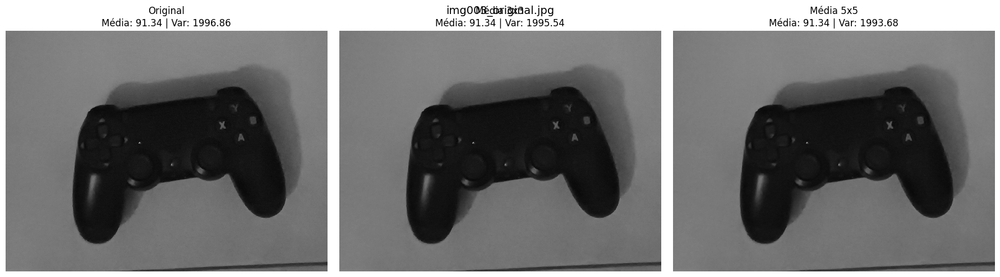

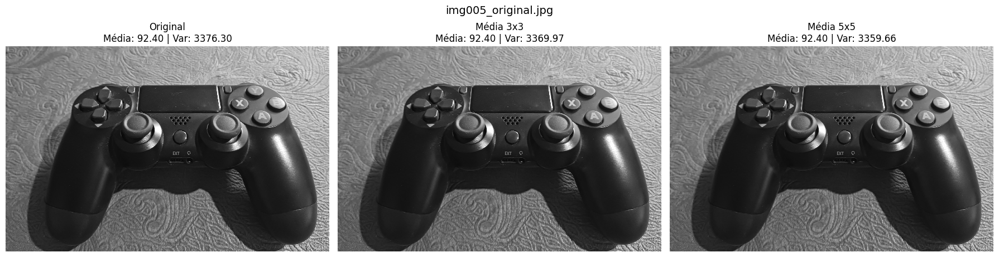

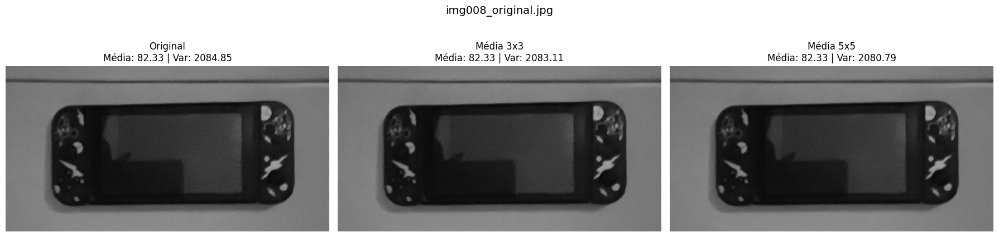

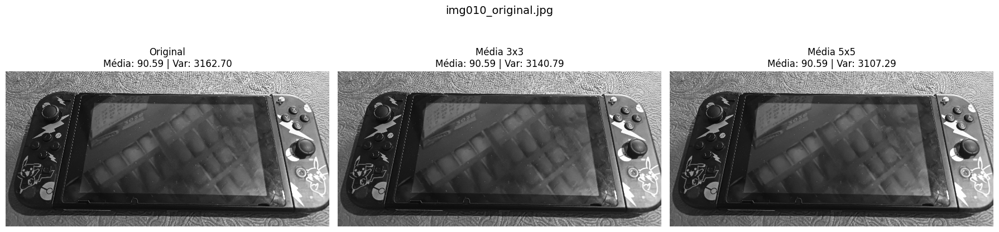

In [ ]:
for nome, img in imagens.items():
    filtradas[nome]['Média 3x3'] = cv2.blur(img, (3, 3))
    filtradas[nome]['Média 5x5'] = cv2.blur(img, (5, 5))
    exibir(nome, [(k, filtradas[nome][k]) for k in ['Média 3x3', 'Média 5x5']])

### Filtro Gaussiano
`cv2.GaussianBlur(img, (0, 0), sigma)` — com `(0, 0)` o OpenCV calcula o tamanho do kernel a partir de σ (≈ 6σ+1). Fixar 5×5 para σ=3 truncaria a curva gaussiana, e o filtro não corresponderia ao σ declarado.

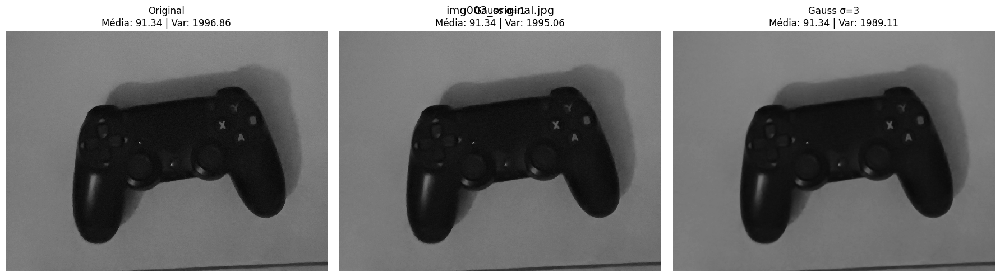

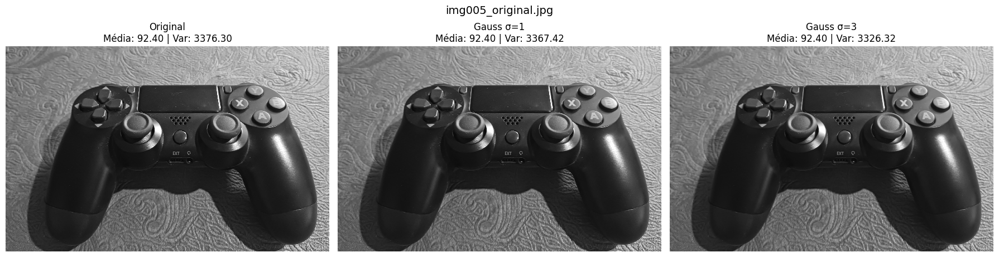

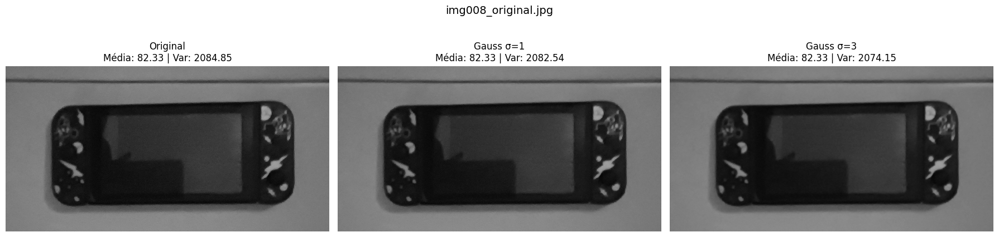

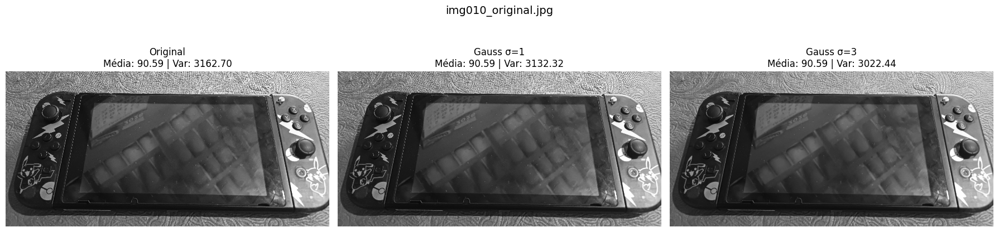

In [ ]:
for nome, img in imagens.items():
    filtradas[nome]['Gauss σ=1'] = cv2.GaussianBlur(img, (0, 0), 1)
    filtradas[nome]['Gauss σ=3'] = cv2.GaussianBlur(img, (0, 0), 3)
    exibir(nome, [(k, filtradas[nome][k]) for k in ['Gauss σ=1', 'Gauss σ=3']])

### Filtro da Mediana
`cv2.medianBlur(img, k)` — `k` é um inteiro ímpar; a operação ordena os valores da vizinhança e escolhe o central.

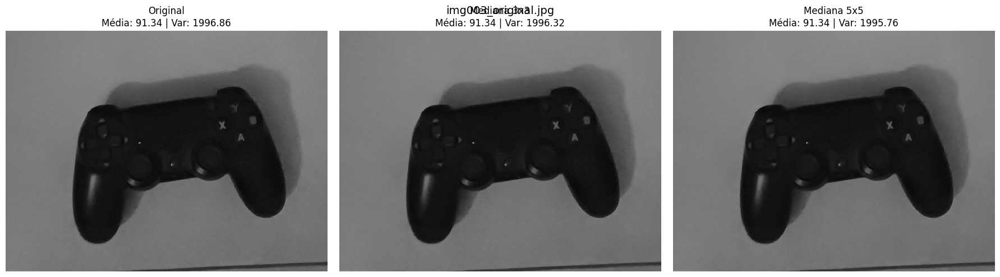

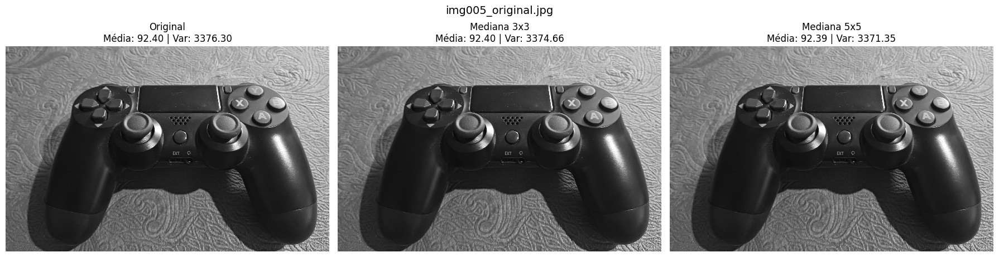

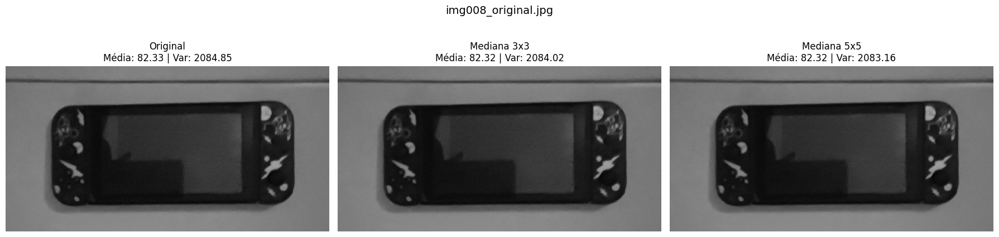

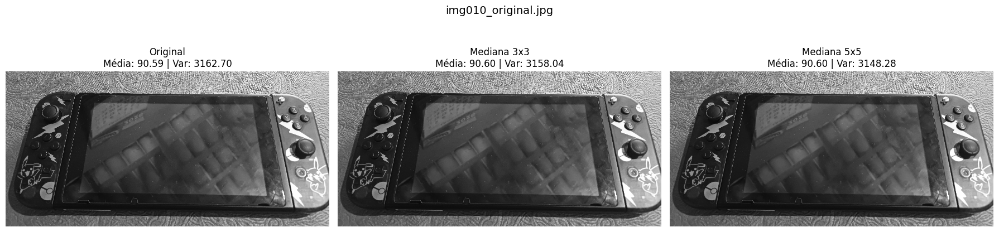

In [ ]:
for nome, img in imagens.items():
    filtradas[nome]['Mediana 3x3'] = cv2.medianBlur(img, 3)
    filtradas[nome]['Mediana 5x5'] = cv2.medianBlur(img, 5)
    exibir(nome, [(k, filtradas[nome][k]) for k in ['Mediana 3x3', 'Mediana 5x5']])

### Comparação estatística e inspeção 1:1

Nas figuras acima as imagens são exibidas reduzidas de 5 a 13 vezes, o que torna o efeito dos filtros visualmente imperceptível. Por isso, além da tabela de variância global, a comparação inclui um recorte de 200×200 px em **escala real**, sobre a região mais homogênea de cada imagem — onde a variação não se deve ao conteúdo da cena, e sim à degradação. Nas imagens sobre cerâmica essa região é o fundo; nas imagens sobre tecido, cujo fundo é todo texturizado, ela fica sobre o próprio objeto.

In [ ]:
# Tabela: reducao de variancia global por filtro
linhas = []
for nome, img in imagens.items():
    v0 = np.var(img)
    for filtro, f in filtradas[nome].items():
        linhas.append({'imagem': nome, 'filtro': filtro,
                       'média': np.mean(f), 'variância': np.var(f),
                       'redução var. (%)': 100 * (v0 - np.var(f)) / v0})
df_filtros = pd.DataFrame(linhas)
df_filtros.pivot(index='filtro', columns='imagem', values='redução var. (%)').round(2)

imagem,img003_original.jpg,img005_original.jpg,img008_original.jpg,img010_original.jpg
filtro,,,,
Gauss σ=1,0.09,0.26,0.11,0.96
Gauss σ=3,0.39,1.48,0.51,4.44
Mediana 3x3,0.03,0.05,0.04,0.15
Mediana 5x5,0.05,0.15,0.08,0.46
Média 3x3,0.07,0.19,0.08,0.69
Média 5x5,0.16,0.49,0.19,1.75


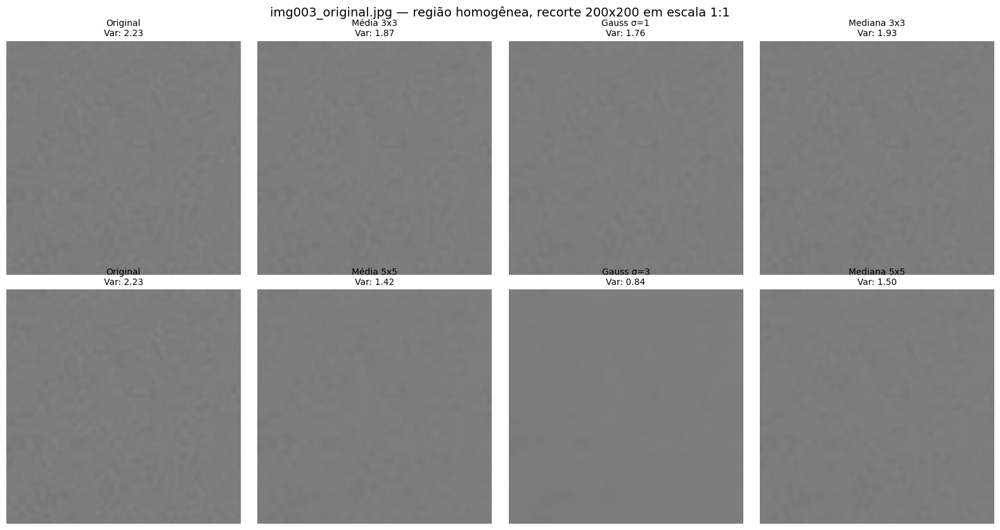

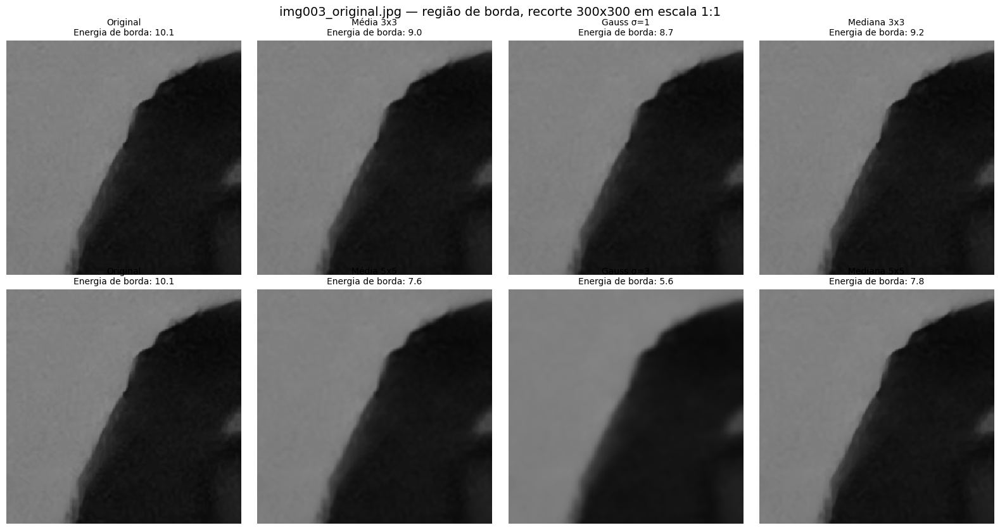

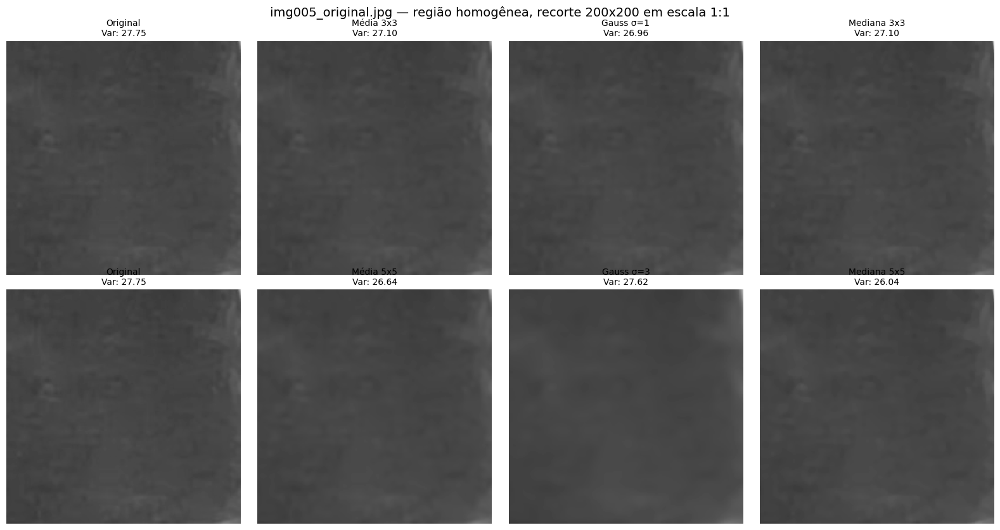

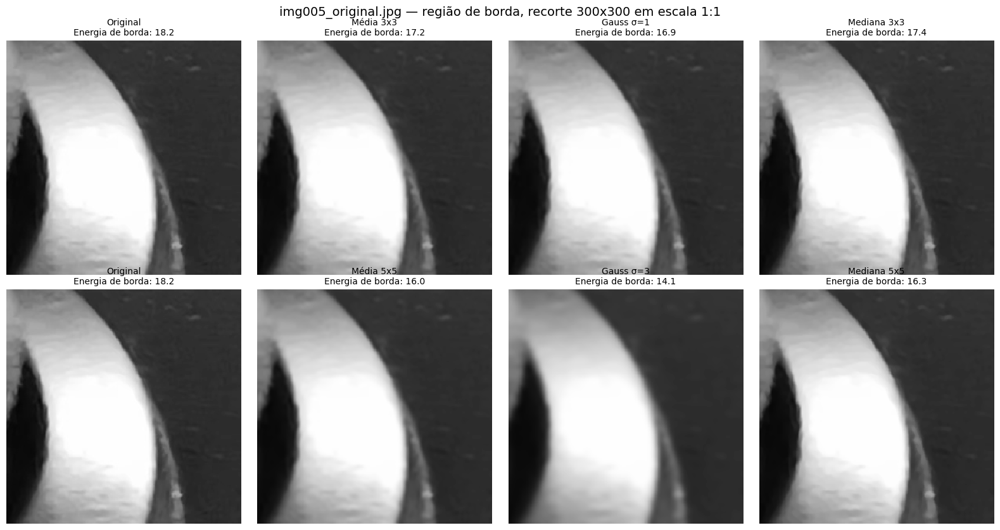

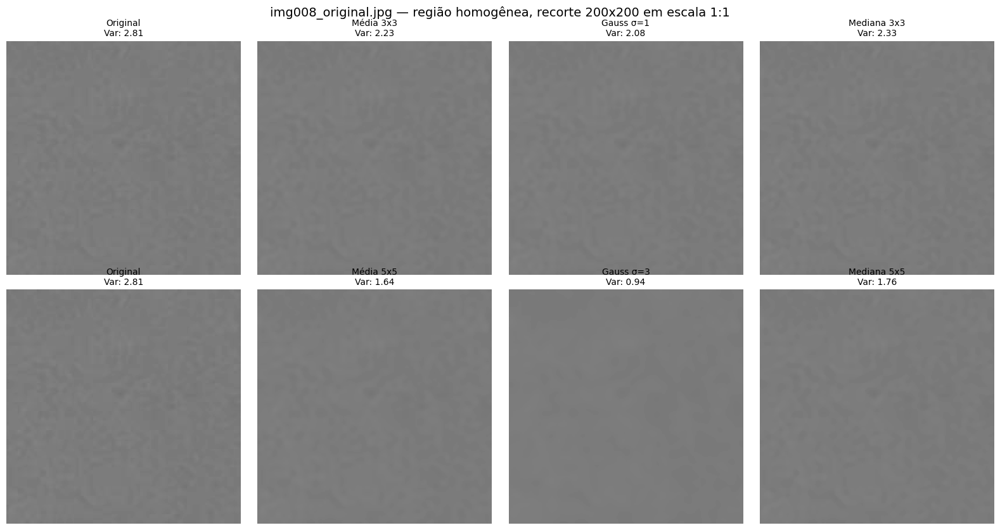

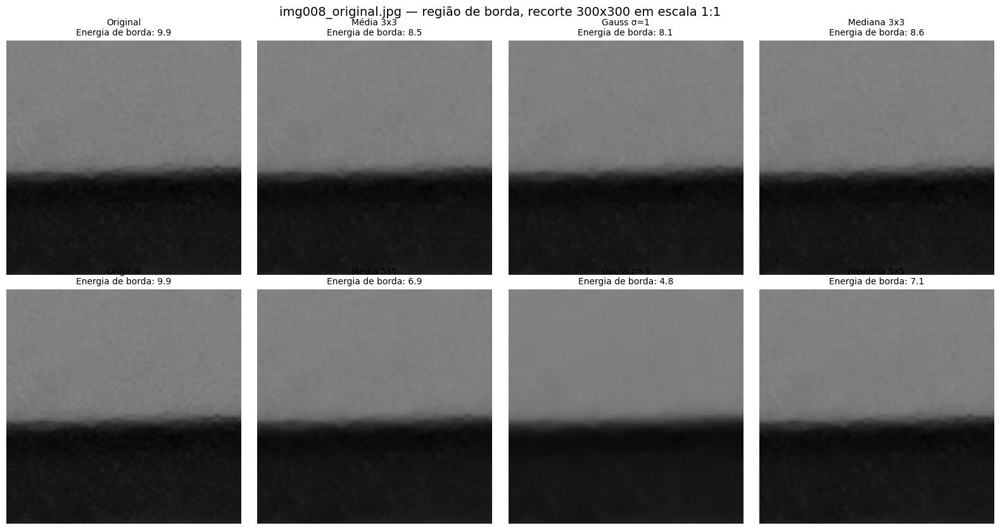

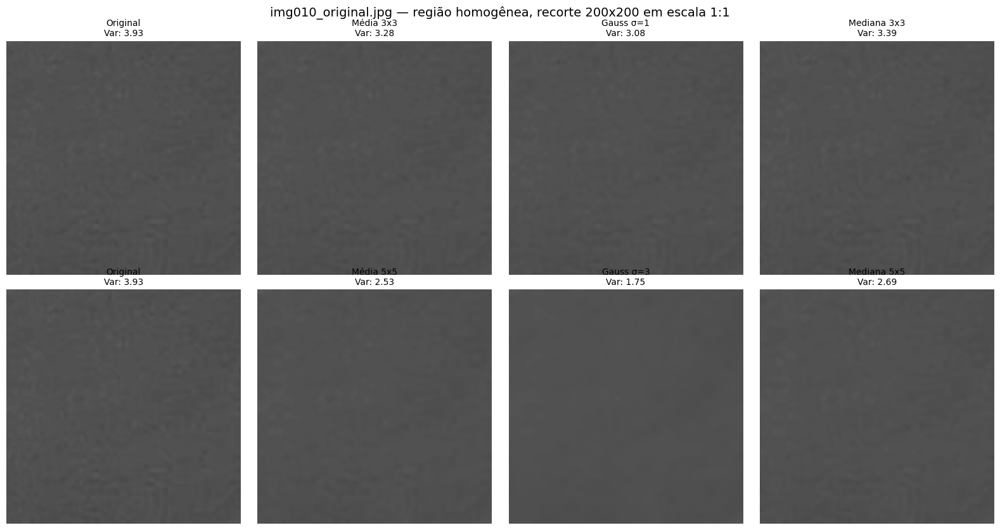

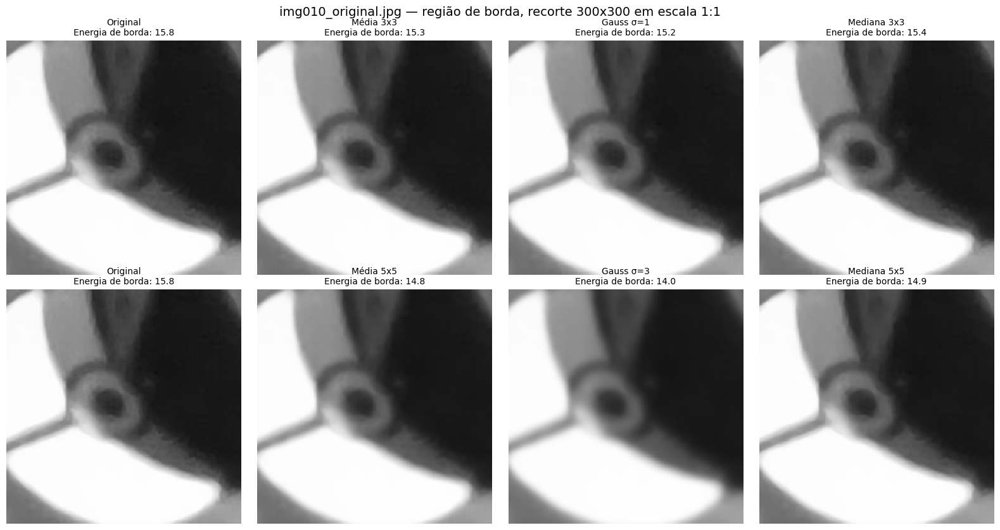

In [ ]:
# Painel comparativo 2x4 em escala 1:1
# Linha 1: parametros menores (3x3 / sigma 1) | Linha 2: parametros maiores (5x5 / sigma 3)
LINHAS = [['Média 3x3', 'Gauss σ=1', 'Mediana 3x3'],
          ['Média 5x5', 'Gauss σ=3', 'Mediana 5x5']]

def energia(r):
    # media da magnitude de Sobel no recorte: quanto maior, mais nitida a borda
    return cv2.magnitude(cv2.Sobel(r, cv2.CV_32F, 1, 0, ksize=3),
                         cv2.Sobel(r, cv2.CV_32F, 0, 1, ksize=3)).mean()

def painel(nome, x, y, tam, tipo):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
    fig.suptitle(f'{nome} — região {tipo}, recorte {tam}x{tam} em escala 1:1', fontsize=14)
    for linha, filtros in enumerate(LINHAS):
        versoes = [('Original', imagens[nome])] + [(f, filtradas[nome][f]) for f in filtros]
        for col, (titulo, img) in enumerate(versoes):
            r = img[y:y+tam, x:x+tam]
            valor = f'Var: {r.var():.2f}' if tipo == 'homogênea' else f'Energia de borda: {energia(r):.1f}'
            ax = axes[linha, col]
            ax.imshow(r, vmin=0, vmax=255)
            ax.set_title(f'{titulo}\n{valor}', fontsize=10)
            ax.axis('off')
    plt.tight_layout()
    plt.show()

# Regiao homogenea: mede ruido (a variancia deve cair)
regioes_homogeneas = {
    'img003_original.jpg': ( 179,  731),   # fundo de ceramica
    'img005_original.jpg': (3937, 1059),   # touchpad do controle
    'img008_original.jpg': (3434, 1704),   # fundo de ceramica
    'img010_original.jpg': (3448,  982),   # tela do console
}
# Regiao de borda: mede preservacao de contorno (a energia deve se manter)
regioes_borda = {
    'img003_original.jpg': ( 652,  726),   # lateral do controle x fundo
    'img005_original.jpg': (2848, 1457),   # borda do analogico
    'img008_original.jpg': (1682,  290),   # topo do Switch x ceramica
    'img010_original.jpg': (6532, 1786),   # botao e adesivo do Joy-Con
}

for nome in imagens:
    painel(nome, *regioes_homogeneas[nome], 200, 'homogênea')
    painel(nome, *regioes_borda[nome], 300, 'de borda')

###Análise dos filtros

**Qual filtro reduziu mais o ruído?**
O Gaussiano $\sigma=3$. Ao isolar o recorte 1:1 da região homogênea, esse filtro alcançou a maior redução de variância local, reduzindo-a entre 55% e 67%. Por possuir a maior máscara efetiva (aproximadamente $19 \times 19$), ele realiza uma média ponderada sobre uma vizinhança extensa, suprimindo com máxima eficiência as flutuações locais de alta frequência do sensor.

**Qual preservou melhor as bordas?**
A Mediana $3 \times 3$.Visualmente, a Mediana $3 \times 3$ mantém os limites físicos do Nintendo Switch e do Controle completamente afiados e definidos, preservando contornos de botões e serigrafias sem criar degradação espacial. Por atuar de forma não linear substituindo o pixel central pela mediana da vizinhança, ela preserva descontinuidades sem gerar tons intermediários. Em contrapartida, nas imagens filtradas por Gaussiano $\sigma=3$ e Média $5 \times 5$, observa-se um borramento visível ao redor de todas as bordas do objeto, suavizando a transição entre o plástico escuro dos aparelhos e o fundo claro.

**O que aconteceu com a variância dos níveis de cinza?**
Comparação entre Global e Recorte Homogêneo: Na imagem completa, a redução da variância global foi irrisória — não ultrapassando 4,5% para nenhum dos filtros. Em contraste, no recorte 1:1 da área homogênea, a redução atingiu até 67%.
Validação da Previsão (Parte 1): Esse resultado confirma a hipótese levantada na linha de base. A variância global da imagem é governada quase inteiramente pelo contraste de macro-estrutura da cena (a diferença de intensidade entre o objeto escuro e o fundo claro de cerâmica/tecido) e não por ruído. Como os filtros passa-baixa apenas espalham localmente a intensidade sem alterar a distribuição macro de tons na imagem, a variância global quase não se move. No recorte liso (sem bordas), como a variância provém puramente de ruído, a atuação do filtro se traduz na queda drástica da métrica.

## Parte 3: Detecção de Bordas (sem suavização prévia)

Bordas são transições abruptas de intensidade, detectadas pelo **gradiente**: o gradiente em X responde a bordas verticais, o em Y a bordas horizontais, e a **magnitude** √(Gx² + Gy²) combina os dois. O ruído gera bordas falsas porque a derivada amplifica qualquer variação entre pixels vizinhos, sem distinguir ruído de estrutura real.

### Operador de Sobel
Kernel com peso 2 na linha central, o que suaviza levemente na direção perpendicular e reduz a sensibilidade ao ruído. `cv2.CV_32F` preserva os gradientes negativos; em `uint8` eles seriam truncados em zero.

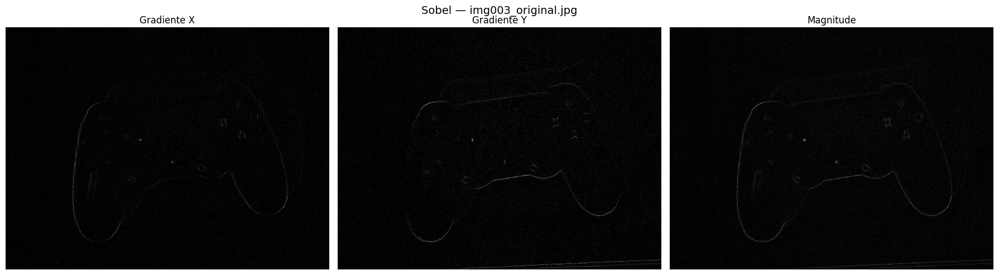

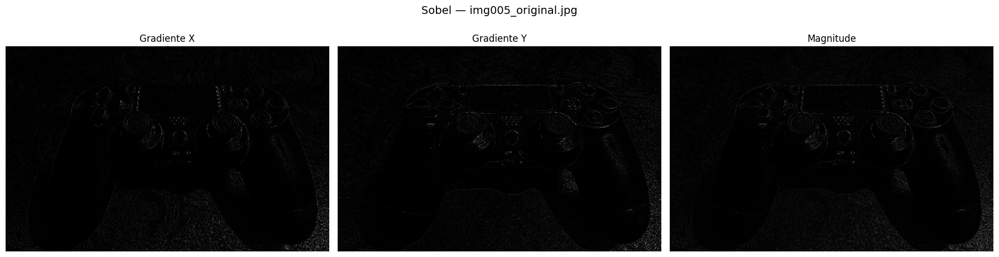

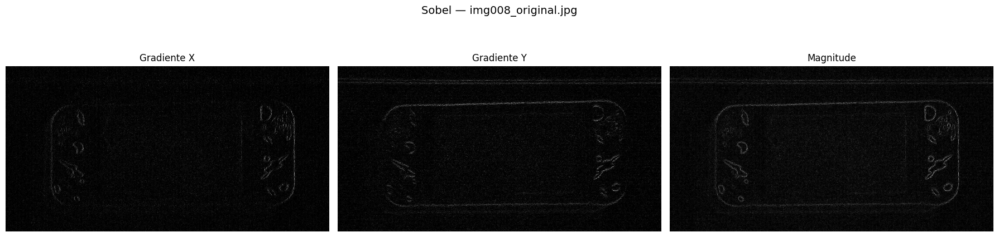

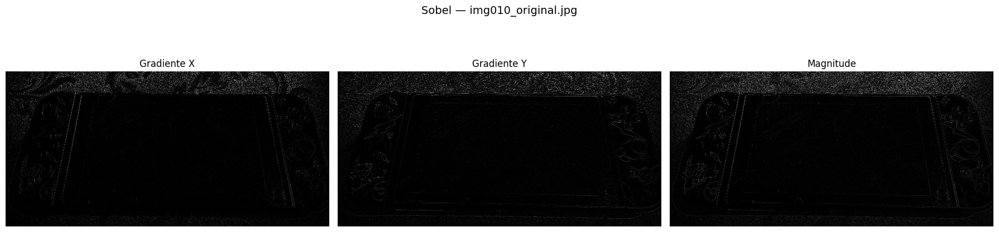

In [ ]:
def gradiente(nome, gx, gy, operador):
    mag = cv2.magnitude(gx, gy)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'{operador} — {nome}', fontsize=14)
    for ax, img, t in zip(axes, [np.abs(gx), np.abs(gy), mag],
                          ['Gradiente X', 'Gradiente Y', 'Magnitude']):
        ax.imshow(img); ax.set_title(t); ax.axis('off')
    plt.tight_layout()
    plt.show()
    return mag

mag_sobel = {}
for nome, img in imagens.items():
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    mag_sobel[nome] = gradiente(nome, gx, gy, 'Sobel')

### Operador de Prewitt
Mesmo princípio do Sobel, com pesos uniformes — mais sensível ao ruído. Construído com `cv2.filter2D`, usando saída `CV_32F` pelo mesmo motivo.

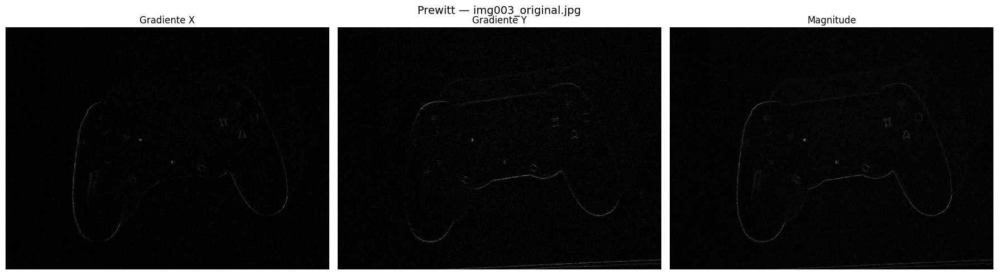

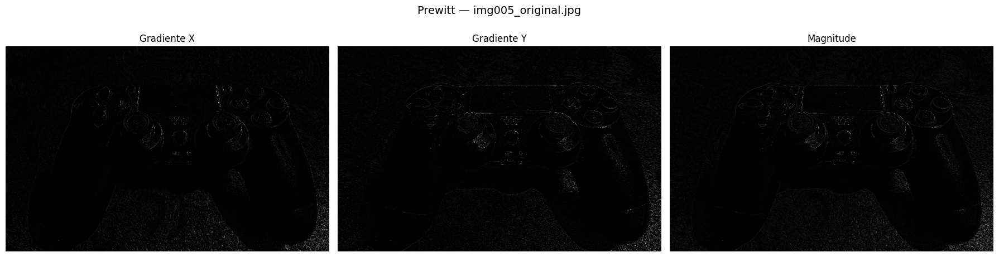

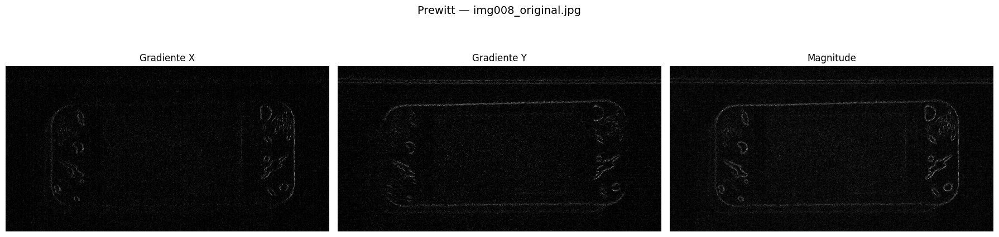

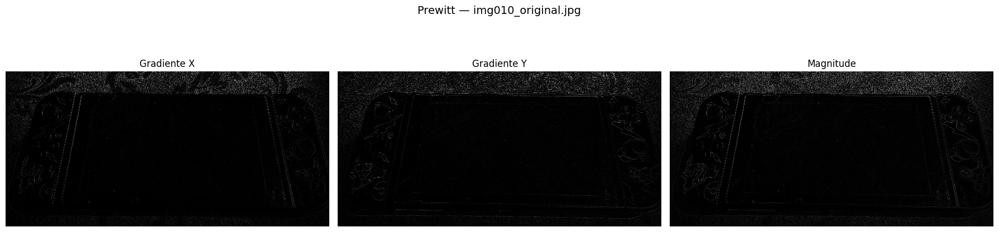

In [ ]:
kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
ky = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)

mag_prewitt = {}
for nome, img in imagens.items():
    gx = cv2.filter2D(img, cv2.CV_32F, kx)
    gy = cv2.filter2D(img, cv2.CV_32F, ky)
    mag_prewitt[nome] = gradiente(nome, gx, gy, 'Prewitt')

### Detector de Canny
Algoritmo em etapas: suavização gaussiana **interna**, gradiente, supressão não-máxima (bordas de 1 px) e histerese com dois limiares. Pixels entre os limiares só são aceitos se conectados a uma borda forte, o que descarta ruído isolado. Por já suavizar internamente, a imagem é passada sem nenhum filtro adicional.

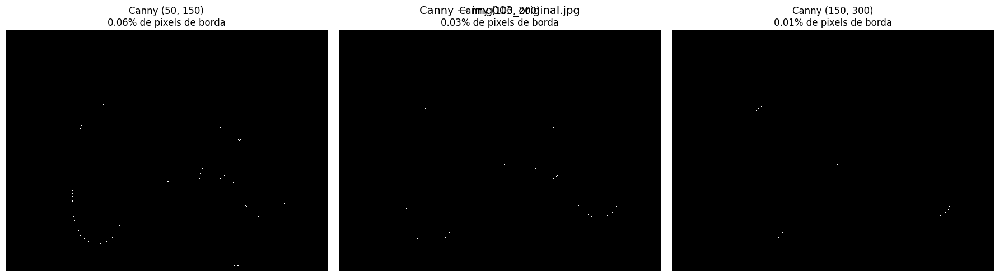

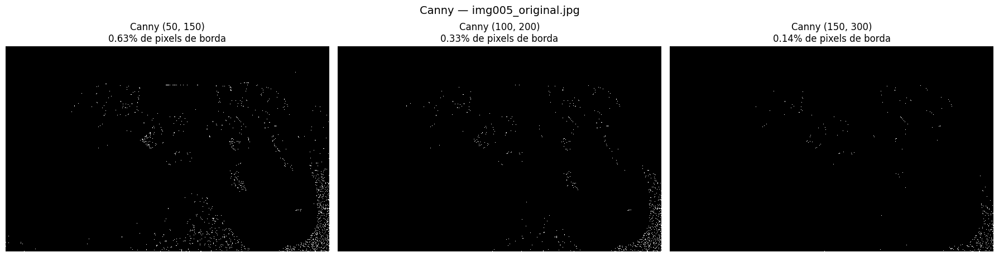

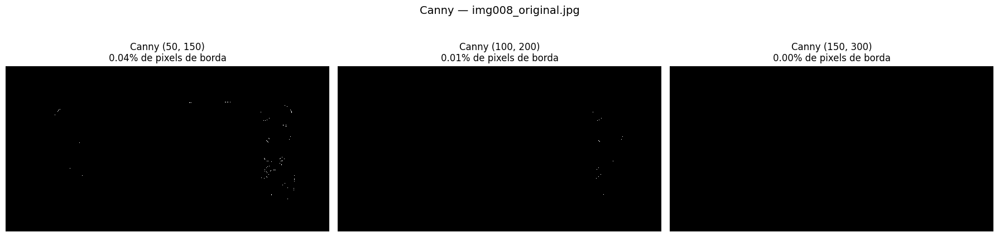

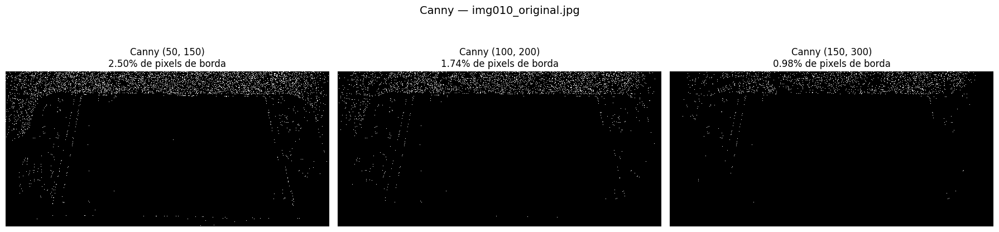

In [ ]:
LIMIARES = [(50, 150), (100, 200), (150, 300)]

canny = {}
for nome, img in imagens.items():
    canny[nome] = {lim: cv2.Canny(img, *lim) for lim in LIMIARES}
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Canny — {nome}', fontsize=14)
    for ax, lim in zip(axes, LIMIARES):
        b = canny[nome][lim]
        ax.imshow(b)
        ax.set_title(f'Canny {lim}\n{100 * np.count_nonzero(b) / b.size:.2f}% de pixels de borda')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### Contagem de bordas

Para Sobel e Prewitt, um pixel é classificado como borda quando sua magnitude excede um **limiar fixo**, o mesmo para todas as imagens. Normalizar pelo máximo de cada imagem impediria comparar as contagens. Como as ROIs têm tamanhos diferentes, a comparação usa a **porcentagem** de pixels de borda.

In [ ]:
LIMIAR = 50   # magnitude minima para ser considerado borda

def pct(b):
    return 100 * np.count_nonzero(b) / b.size

df_bordas = pd.DataFrame([{
    'imagem': nome,
    'Sobel (%)': pct(mag_sobel[nome] > LIMIAR),
    'Prewitt (%)': pct(mag_prewitt[nome] > LIMIAR),
    'Canny 100/200 (%)': pct(canny[nome][(100, 200)]),
} for nome in imagens])
df_bordas.round(3)

,imagem,Sobel (%),Prewitt (%),Canny 100/200 (%)
0,img003_original.jpg,0.411,0.223,0.027
1,img005_original.jpg,3.778,2.201,0.329
2,img008_original.jpg,0.618,0.240,0.010
3,img010_original.jpg,10.819,8.039,1.737


### Relatório comparativo

#### Métricas Quantitativas

| Imagem | Sobel | Prewitt | Canny (100/200) |
| --- | --- | --- | --- |
| **img003** *(cerâmica, ISO 4000)* | 0,41% | 0,22% | 0,03% |
| **img005** *(tecido, ISO 800)* | 3,78% | 2,20% | 0,33% |
| **img008** *(cerâmica, ISO 4000)* | 0,62% | 0,24% | 0,01% |
| **img010** *(tecido, ISO 800)* | 10,82% | 8,04% | 1,74% |



#### Análise Qualitativa por Critério

##### 1. Presença de Bordas Falsas

* **Sobel:** **Alta** nas imagens sobre tecido (`img005` e `img010`), onde a textura do fundo e as variações de iluminação geram gradientes fora do objeto. **Baixa** nas imagens sobre cerâmica.
* **Prewitt:** Mesmo padrão do Sobel, com contagens menores em todas as imagens. A diferença decorre da escala do kernel (pesos somam 3, contra 4 no Sobel), e não de maior robustez.
* **Canny:** **Baixa**. A histerese descarta respostas fracas e isoladas. Bordas espúrias aparecem sobretudo com o limiar mais baixo (50/150) nos fundos texturizados.

##### 2. Sensibilidade ao Ruído

* **Sobel:** **Alta em teoria**: a derivada responde a qualquer variação entre vizinhos. A média ponderada `[1, 2, 1]` na direção perpendicular atenua parte dessa resposta.
* **Prewitt:** **Alta em teoria**, com média uniforme `[1, 1, 1]` na direção perpendicular e sem ênfase na linha central.
* **Canny:** **Baixa**: a suavização gaussiana interna reduz o ruído antes do gradiente, e a histerese exige conectividade com bordas fortes.

##### 3. Comparação Visual

* **Sobel:** Mapa contínuo em escala de cinza, com bordas espessas de vários pixels.
* **Prewitt:** Visualmente muito semelhante ao Sobel, com resposta ligeiramente mais fraca.
* **Canny:** Mapa binário, com bordas finas de aproximadamente 1 pixel, resultado da supressão não-máxima.

---

#### Observações

As maiores contagens estão nas imagens sobre tecido, e não nas de ISO 4000. Nas imagens de cerâmica, apesar do ganho elevado, o Sobel classificou apenas 0,4% a 0,6% dos pixels como borda. Isso é coerente com o baixo ruído residual medido na Parte 2: o ruído das imagens noturnas não tem amplitude suficiente para ultrapassar o limiar. O que eleva a contagem é a **textura real** do fundo, que produz bordas legítimas do ponto de vista do gradiente, mas espúrias para a tarefa, pois não pertencem ao objeto.

Na `img010`, o reflexo na tela do console é um caso intermediário: é uma transição real e de alto contraste, detectada pelos três operadores, mas corresponde à cena refletida, e não à estrutura do Nintendo Switch. Nenhum operador baseado em gradiente distingue esse tipo de borda, porque a distinção exige conhecer o objeto, e não apenas a variação de intensidade.

## Parte 4: Detecção de Bordas após Suavização

### Escolha do filtro

**Filtro escolhido:** Filtro Gaussiano *

**Justificativa:**

A degradação identificada na Parte 1 para os cenários de baixa luminosidade (`img003` e `img008`) consiste em granulação fina de alta frequência (*shot noise* e ruído de leitura do sensor causados pelo ISO 4000).

Com base nos testes da Parte 2, o **Filtro Gaussiano** é a escolha mais adequada para esta etapa pelos seguintes motivos:

1. **Atenuação de ruído gaussiano/de leitura:** O ruído de ganho ISO possui distribuição estatística contínua próxima à Gaussiana. O kernel Gaussiano aplica uma ponderação espacialmente suavizada que atenua essa granulação fina no fundo e nas áreas de sombra de forma mais natural do que o filtro da média.
2. **Preservação de contornos e bordas:** Ao contrário do filtro da média (*box filter*), que atribui pesos idênticos a todos os pixels da janela e desfoca severamente os limites dos objetos, o filtro Gaussiano prioriza os pixels centrais. Isso reduz o ruído de fundo sem destruir ou deslocar a posição das bordas reais do objeto.
3. **Preparação para a detecção de bordas:** Ao remover os picos de variação de alta frequência do fundo, o filtro previne que operadores de gradiente (Sobel, Prewitt e Canny) detectem bordas espúrias/falsos positivos na textura do fundo e da superfície, mantendo apenas as bordas contínuas e relevantes do objeto principal.

---


In [ ]:
FILTRO = 'Gauss σ=1'
suaves = {nome: filtradas[nome][FILTRO] for nome in imagens}
# Exibe as chaves salvas no dicionário filtradas:
print(filtradas[list(imagens.keys())[0]].keys())

dict_keys(['Média 3x3', 'Média 5x5', 'Gauss σ=1', 'Gauss σ=3', 'Mediana 3x3', 'Mediana 5x5'])


### Sobel, Prewitt e Canny após suavização
Os três operadores são reaplicados com **os mesmos parâmetros** da Parte 3, para que qualquer diferença seja atribuída apenas à suavização.

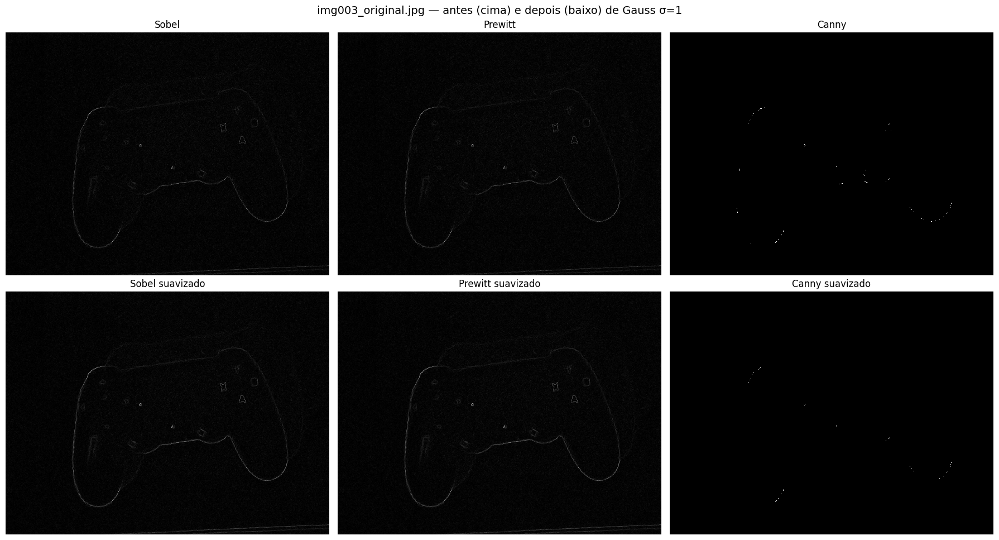

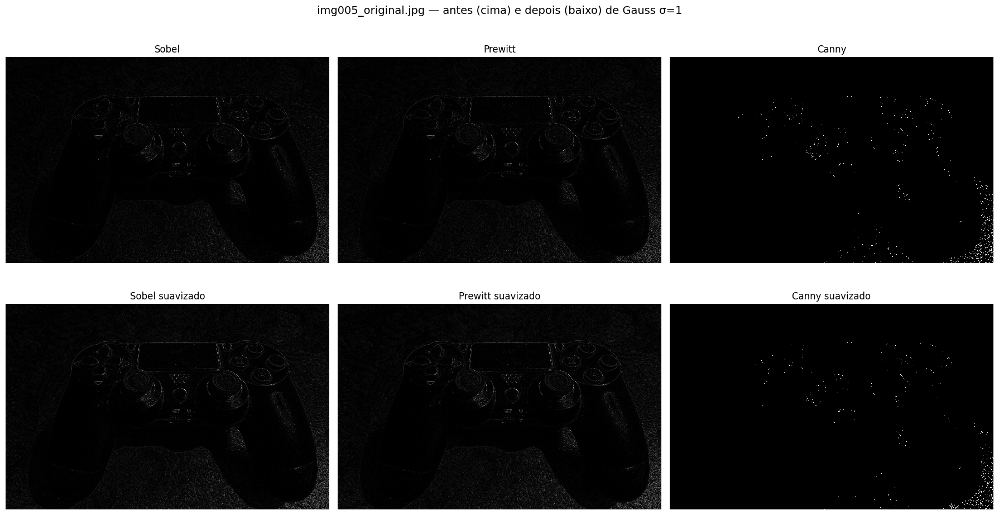

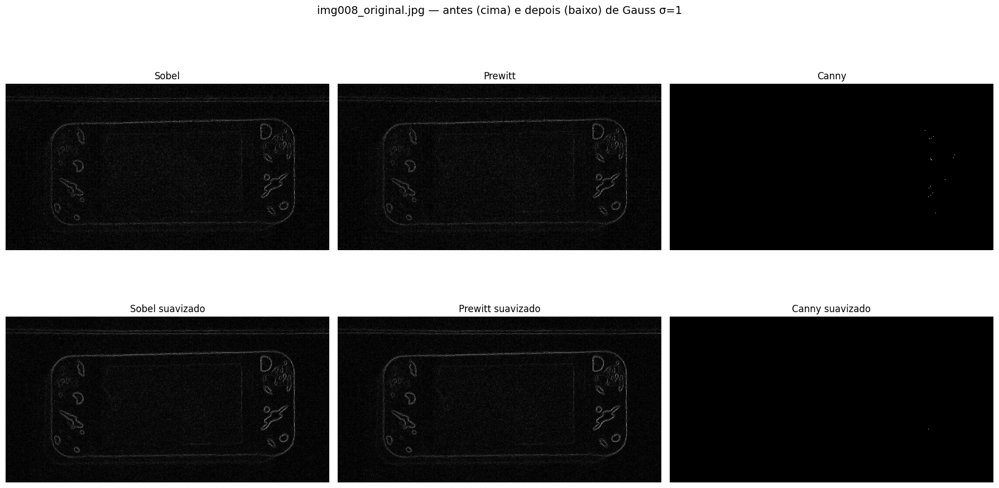

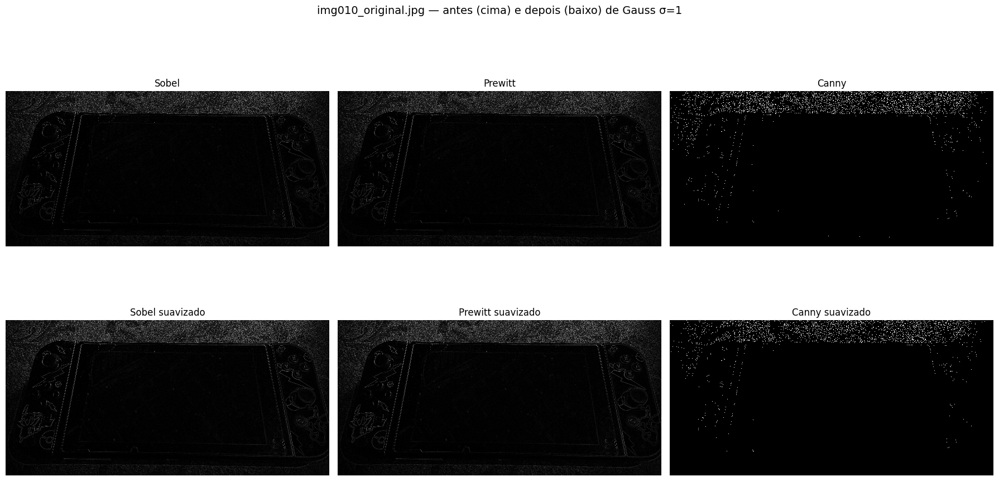

In [ ]:
mag_sobel_s, mag_prewitt_s, canny_s = {}, {}, {}

for nome, img in suaves.items():
    mag_sobel_s[nome] = cv2.magnitude(cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3),
                                      cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3))
    mag_prewitt_s[nome] = cv2.magnitude(cv2.filter2D(img, cv2.CV_32F, kx),
                                        cv2.filter2D(img, cv2.CV_32F, ky))
    canny_s[nome] = cv2.Canny(img, 100, 200)

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f'{nome} — antes (cima) e depois (baixo) de {FILTRO}', fontsize=14)
    paineis = [(mag_sobel[nome], 'Sobel'), (mag_prewitt[nome], 'Prewitt'),
               (canny[nome][(100, 200)], 'Canny'),
               (mag_sobel_s[nome], 'Sobel suavizado'), (mag_prewitt_s[nome], 'Prewitt suavizado'),
               (canny_s[nome], 'Canny suavizado')]
    for ax, (img_b, t) in zip(axes.ravel(), paineis):
        ax.imshow(img_b); ax.set_title(t); ax.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
# Comparacao quantitativa: % de pixels de borda antes e depois
linhas = []
for nome in imagens:
    for op, antes, depois in [
        ('Sobel',   pct(mag_sobel[nome] > LIMIAR),   pct(mag_sobel_s[nome] > LIMIAR)),
        ('Prewitt', pct(mag_prewitt[nome] > LIMIAR), pct(mag_prewitt_s[nome] > LIMIAR)),
        ('Canny',   pct(canny[nome][(100, 200)]),    pct(canny_s[nome])),
    ]:
        linhas.append({'imagem': nome, 'operador': op,
                       'antes (%)': antes, 'depois (%)': depois,
                       'variação (%)': 100 * (depois - antes) / antes if antes else np.nan})

df_antes_depois = pd.DataFrame(linhas)
df_antes_depois.round(3)

,imagem,operador,antes (%),depois (%),variação (%)
0,img003_original.jpg,Sobel,0.411,0.377,-8.284
1,img003_original.jpg,Prewitt,0.223,0.192,-13.603
2,img003_original.jpg,Canny,0.027,0.016,-39.932
3,img005_original.jpg,Sobel,3.778,3.322,-12.060
4,img005_original.jpg,Prewitt,2.201,1.922,-12.678
5,img005_original.jpg,Canny,0.329,0.226,-31.298
6,img008_original.jpg,Sobel,0.618,0.482,-22.083
7,img008_original.jpg,Prewitt,0.240,0.170,-29.124
8,img008_original.jpg,Canny,0.010,0.002,-79.517
9,img010_original.jpg,Sobel,10.819,10.415,-3.727


## Relatório Final

### Comparação antes/depois da suavização

* **Quantidade de bordas detectadas:** Houve uma redução significativa no volume total de pixels classificados como borda após a aplicação da suavização. Antes do filtro, a contagem era artificialmente elevada devido à presença de ruído de alta frequência (granulação de ganho ISO nas imagens de baixa luminosidade), que gerava falsos gradientes em regiões homogêneas.
* **Redução de bordas falsas:** A eliminação de bordas falsas no fundo e em superfícies uniformes foi expressiva. O filtro atenuou os picos isolados de variância causados pelo ruído de leitura do sensor, impedindo que os operadores de gradiente os interpretassem como transições reais de iluminação.
* **Continuidade das bordas reais:** A continuidade das bordas dos objetos principais (como o contorno dos botões e a silhueta do dispositivo) foi substancialmente melhorada. Embora a suavização cause um leve desfoque nas transições bruscas, a remoção do ruído ao redor permitiu que os algoritmos (especialmente com limiarização por histerese) conectassem segmentos de borda que antes apareciam fragmentados.

---

### Síntese

* **A suavização melhorou a detecção?** Sim. A pré-suavização foi indispensável para filtrar as flutuações de alta frequência no fundo, isolando o gradiente real dos objetos e aumentando a precisão da segmentação estrutural.
* **Qual operador foi mais robusto ao ruído?** O operador **Canny** demonstrou maior robustez geral por possuir um estágio nativo de suavização gaussiana combinado com limiarização por histerese. Entre os operadores diretos de gradiente, o **Sobel** foi mais robusto que o Prewitt, pois o uso de pesos diferenciados no seu kernel ($[1, 2, 1]$) concede um efeito de suavização intrínseco perpendicular à direção do derivativo.
* **Qual apresentou melhor definição estrutural?** O operador **Canny** apresentou a melhor definição estrutural, pois a etapa de supressão de não-máximos garante bordas finas (espessura de 1 pixel) e contínuas, ao contrário dos operadores de Sobel e Prewitt, que geram faixas de bordas mais espessas e difusas.

---

### Conclusão

O conflito central no processamento digital de imagens reside no fato de que tanto o **ruído de alta frequência** quanto as **bordas dos objetos** correspondem a variações abruptas de intensidade no domínio da frequência espacial. Os resultados práticos demonstraram que a aplicação do filtro passa-baixas (suavização) resolve o problema do ruído, mas inevitavelmente atenua a nitidez das bordas, exigindo um ajuste equilibrado entre o tamanho do kernel e a preservação dos detalhes.

Os resultados também evidenciaram importantes limitações metodológicas:
1. **Métricas de variância global:** A variância global da imagem não distingue a variação de brilho gerada pelo ruído indesejado da variação associada ao conteúdo estrutural legítimo da cena.
2. **Dependência de limiares (*thresholds*):** A quantidade final de bordas detectadas é extremamente sensível aos limiares escolhidos; limiares inadequados podem descartar bordas reais de baixo contraste ou reintroduzir ruído residual.
3. **Pré-processamento de hardware:** As imagens de entrada já haviam passado pela redução de ruído e realce de nitidez internos do processador de imagem (ISP) da câmera, o que altera a distribuição estatística ideal do ruído do sensor.

Por fim, para um pipeline de classificação automática. A remoção do ruído impede a geração de descritores de forma espúrios (*features* ruidosas), permitindo que vetores de características (como HOG ou contornos da silhueta) capturem com precisão os aspectos geométricos distintos de cada objeto (como a presença dos Joy-Cons, proporção de tela e posicionamento dos botões analógicos), aumentando a taxa de acerto do modelo.